# 05 - Analisis Kesenjangan & Agglomerative Clustering

**Tujuan**
1. Mengukur ketimpangan faskes (Gini, Theil-T, CV, rasio max/min, share top-5).
2. Menganalisis gap kebutuhan puskesmas terhadap standar Permenkes.
3. Menjalankan **agglomerative clustering (Ward linkage)** pada 5 fitur pemerataan.
4. Memilih jumlah klaster dengan silhouette score, lalu menginterpretasikan tiap klaster.
5. Menyimpan tabel klaster dan figur untuk laporan/dashboard.

**Input**: `data/processed/faskes_features.csv` (dibuat pada notebook 03).

## 0. Setup

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
from scipy.cluster.hierarchy import linkage, dendrogram

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titleweight"] = "bold"

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED = ROOT / "data" / "processed"
FIG_DIR = ROOT / "outputs" / "figures"
TABLE_DIR = ROOT / "outputs" / "tables"
for d in (FIG_DIR, TABLE_DIR):
    d.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(PROCESSED / "faskes_features.csv")
CLUSTER_COLS = ["pkm_per100k", "rs_per100k", "log_faskes_per_1000km2", "desa_pkm_pct", "desa_rs_pct"]
SCALED_COLS = ["scaled_pkm_per100k", "scaled_rs_per100k", "scaled_log_density",
               "scaled_desa_pkm_pct", "scaled_desa_rs_pct"]
X = df[SCALED_COLS].to_numpy()
print("Jumlah provinsi:", len(df), "| Fitur:", len(SCALED_COLS))

Jumlah provinsi: 38 | Fitur: 5


## 1. Ketimpangan antarprovinsi

,gini,theil_t,cv,max_min_ratio,top5_share_pct
indikator,,,,,
total_faskes_est,0.4285,0.3329,0.9733,20.56,41.48
pkm_per100k,0.3341,0.1804,0.6238,44.70,28.83
rs_per100k,0.1747,0.0478,0.3134,4.41,20.27
desa_pkm_pct,0.1685,0.0483,0.3212,4.94,21.07
faskes_per_1000km2,0.7056,1.2078,2.6966,431.11,66.30


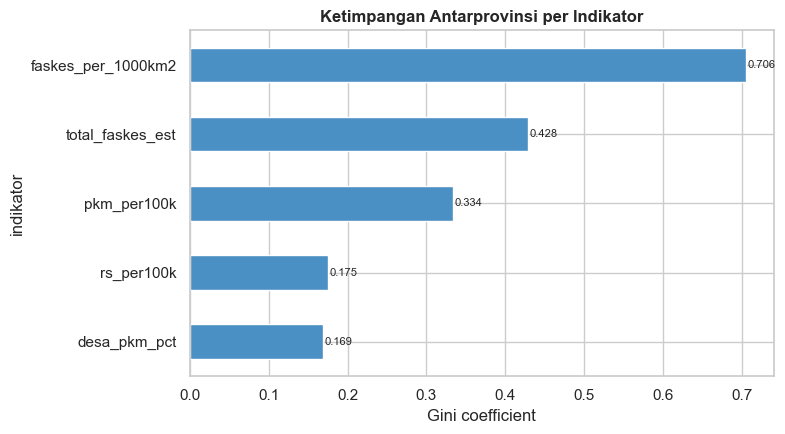

In [2]:
def gini(x):
    x = np.sort(np.asarray(x, dtype=float))
    n = len(x)
    total = x.sum()
    if total == 0:
        return 0.0
    idx = np.arange(1, n + 1)
    return np.sum((2 * idx - n - 1) * x) / (n * total)

def theil_t(x):
    x = np.asarray(x, dtype=float)
    x = x[x > 0]
    mu = x.mean()
    return np.mean((x / mu) * np.log(x / mu))

VARS = ["total_faskes_est", "pkm_per100k", "rs_per100k", "desa_pkm_pct", "faskes_per_1000km2"]
rows = []
for var in VARS:
    v = df[var].dropna()
    rows.append({
        "indikator": var,
        "gini": round(gini(v), 4),
        "theil_t": round(theil_t(v), 4),
        "cv": round(v.std() / v.mean(), 4),
        "max_min_ratio": round(v.max() / v.min(), 2),
        "top5_share_pct": round(v.sort_values(ascending=False).head(5).sum() / v.sum() * 100, 2),
    })
inequality = pd.DataFrame(rows).set_index("indikator")
inequality.to_csv(TABLE_DIR / "inequality_metrics.csv")
display(inequality)

fig, ax = plt.subplots(figsize=(8, 4.5))
inequality["gini"].sort_values().plot.barh(ax=ax, color="#4a90c4")
ax.set_xlabel("Gini coefficient")
ax.set_title("Ketimpangan Antarprovinsi per Indikator", weight="bold")
for i, v in enumerate(inequality["gini"].sort_values()):
    ax.text(v + 0.002, i, f"{v:.3f}", va="center", fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "gini_indikator.png", dpi=150)
plt.show()

**Interpretasi**: Nilai Gini mendekati 0 berarti merata, mendekati 1 berarti timpang.
Indikator dengan Gini dan rasio max/min tertinggi menjadi prioritas pemerataan.
Theil-T menambahkan sensitivitas terhadap perbedaan antarprovinsi berpopulasi besar.

## 2. Gap kebutuhan puskesmas

10 defisit puskesmas terbesar:


,Provinsi,pkm_gap,pkm_needed,total_pkm,desa_pkm_pct,desa_rs_pct,status
18,Nusa Tenggara Timur,246.713333,194.286667,441,12.295082,1.865461,Defisit
27,Sulawesi Tenggara,212.000000,96.000000,308,13.438045,1.570681,Defisit
0,Aceh,176.136667,189.863333,366,5.665592,1.090127,Defisit
30,Maluku,174.493333,66.506667,241,18.700475,2.377179,Defisit
26,Sulawesi Selatan,151.956667,322.043333,474,15.849673,3.888889,Defisit
37,Papua Pegunungan,132.936667,50.063333,183,5.542901,0.341686,Defisit
25,Sulawesi Tengah,112.673333,106.326667,219,10.979228,1.928783,Defisit
24,Sulawesi Utara,111.650000,91.350000,203,11.262242,3.046790,Defisit
20,Kalimantan Tengah,109.016667,95.983333,205,13.316424,1.712112,Defisit
6,Bengkulu,106.890000,72.110000,179,11.830800,1.652346,Defisit



Provinsi surplus (gap negatif):


,Provinsi,pkm_gap,pkm_needed,total_pkm,desa_pkm_pct,desa_rs_pct,status
11,Jawa Barat,-599.463333,1705.463333,1106,18.499245,6.160819,Surplus
14,Jawa Timur,-435.733333,1411.733333,976,11.537556,4.461973,Surplus
12,Jawa Tengah,-404.500000,1285.500000,881,10.405232,3.830433,Surplus
10,DKI Jakarta,-311.656667,355.656667,44,15.730337,46.816479,Surplus
15,Banten,-168.376667,421.376667,253,16.172680,7.280928,Surplus
16,Bali,-29.606667,149.606667,120,16.991643,8.774373,Surplus
17,Nusa Tenggara Barat,-16.843333,193.843333,177,15.084746,3.559322,Surplus
13,DI Yogyakarta,-5.756667,126.756667,121,27.397260,15.525114,Surplus


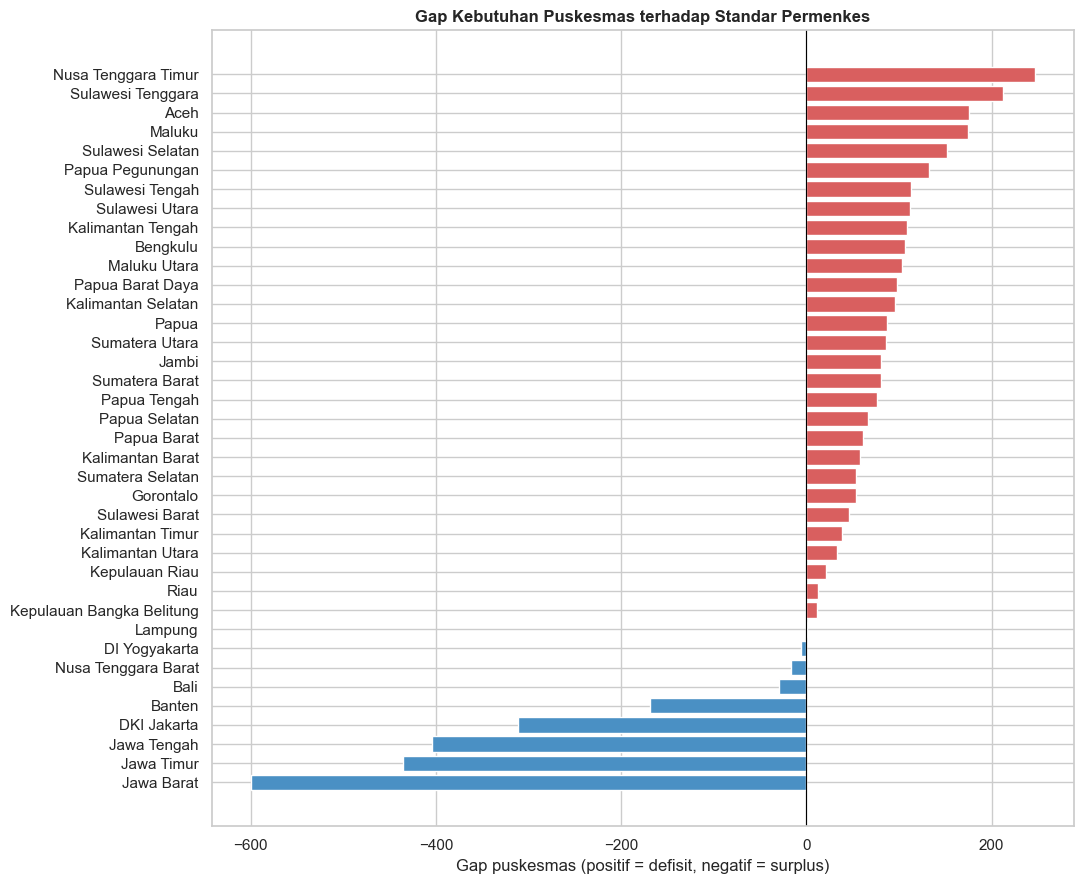

In [3]:
gap = df[["Provinsi", "pkm_gap", "pkm_needed", "total_pkm", "desa_pkm_pct", "desa_rs_pct"]].copy()
gap["status"] = np.where(gap["pkm_gap"] > 0, "Defisit", "Surplus")

print("10 defisit puskesmas terbesar:")
display(gap.sort_values("pkm_gap", ascending=False).head(10))

print("\nProvinsi surplus (gap negatif):")
display(gap[gap["pkm_gap"] < 0].sort_values("pkm_gap"))

fig, ax = plt.subplots(figsize=(11, 9))
g = gap.sort_values("pkm_gap")
colors = ["#4a90c4" if v < 0 else "#d95f5f" for v in g["pkm_gap"]]
ax.barh(g["Provinsi"], g["pkm_gap"], color=colors)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Gap puskesmas (positif = defisit, negatif = surplus)")
ax.set_title("Gap Kebutuhan Puskesmas terhadap Standar Permenkes", weight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "gap_puskesmas.png", dpi=150)
plt.show()

gap.to_csv(TABLE_DIR / "gap_puskesmas.csv", index=False)

**Catatan**: `pkm_gap` memakai standar 1 puskesmas per 30.000 penduduk (Permenkes).
Gap negatif berarti ketersediaan melampaui standar populasi, **bukan** berarti
kelebihan secara geografis — provinsi kepulauan bisa surplus per kapita tetapi
tetap sulit dijangkau.

## 3. Agglomerative clustering (Ward)

### 3.1 Dendrogram

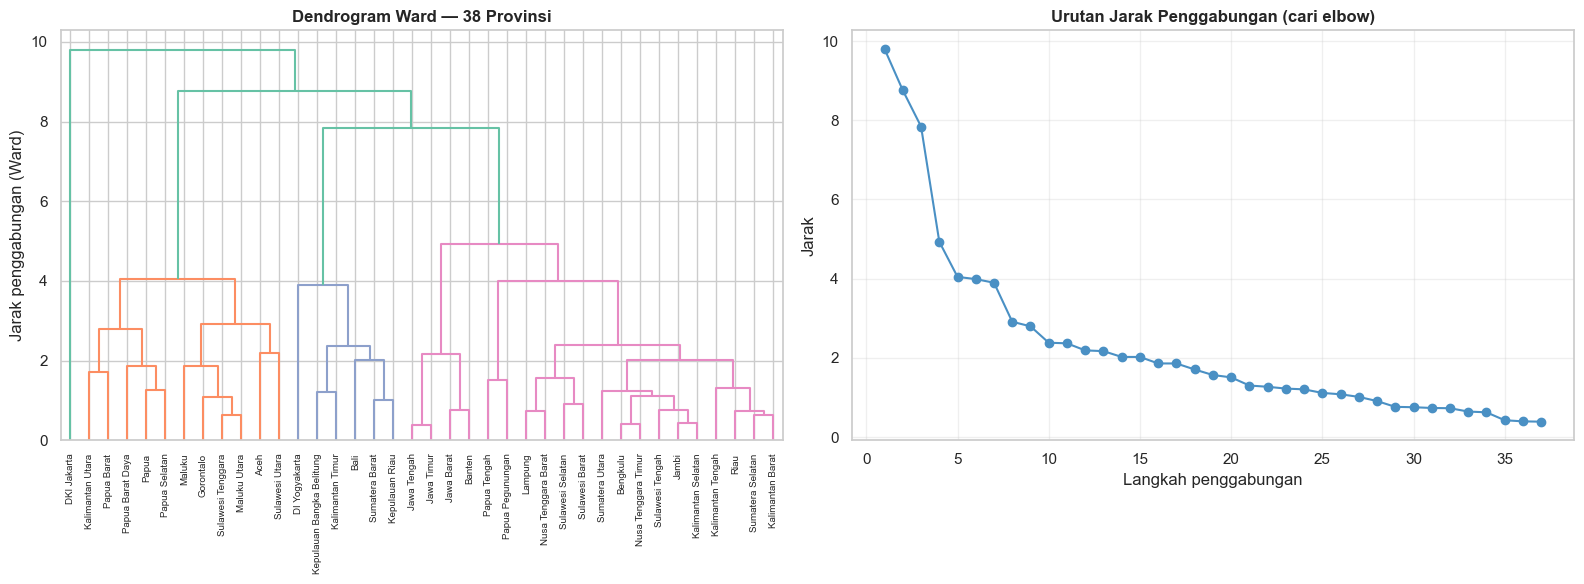

In [4]:
Z = linkage(X, method="ward")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
dendrogram(Z, labels=df["Provinsi"].tolist(), leaf_rotation=90, leaf_font_size=7, ax=axes[0])
axes[0].set_title("Dendrogram Ward — 38 Provinsi", weight="bold")
axes[0].set_ylabel("Jarak penggabungan (Ward)")

dist = np.sort(Z[:, 2])[::-1]
axes[1].plot(range(1, len(dist) + 1), dist, "o-", color="#4a90c4")
axes[1].set_title("Urutan Jarak Penggabungan (cari elbow)", weight="bold")
axes[1].set_xlabel("Langkah penggabungan")
axes[1].set_ylabel("Jarak")
axes[1].grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / "dendrogram_ward.png", dpi=150)
plt.show()

### 3.2 Pemilihan jumlah klaster

,k,silhouette,calinski_harabasz,davies_bouldin
0,2,0.622,12.169,0.252
1,3,0.255,14.573,0.958
2,4,0.293,18.198,0.862
3,5,0.252,17.555,0.873
4,6,0.233,16.737,1.014
5,7,0.248,16.845,0.958


k terpilih (silhouette tertinggi, k>=3): 4


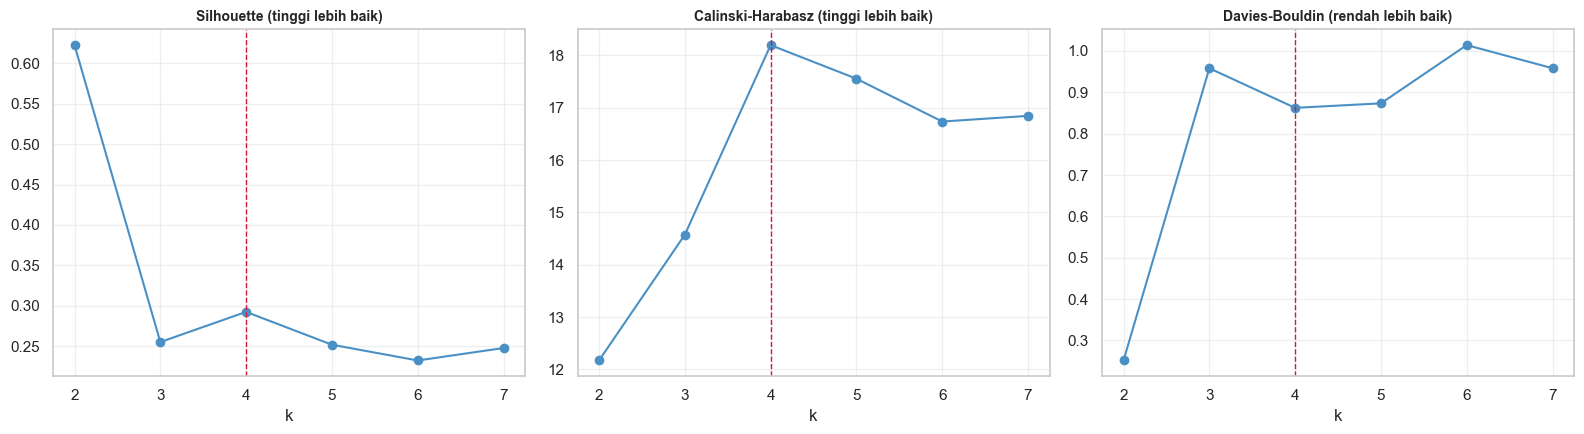

In [5]:
scores = []
for k in range(2, 8):
    model_k = AgglomerativeClustering(n_clusters=k, linkage="ward")
    labels_k = model_k.fit_predict(X)
    scores.append({
        "k": k,
        "silhouette": silhouette_score(X, labels_k),
        "calinski_harabasz": calinski_harabasz_score(X, labels_k),
        "davies_bouldin": davies_bouldin_score(X, labels_k),
    })
scores = pd.DataFrame(scores)
display(scores.round(3))

# k=2 didominasi pemisahan DKI Jakarta vs sisanya (degenerate).
# Pilih k>=3 dengan silhouette tertinggi.
valid = scores[scores["k"] >= 3].sort_values("silhouette", ascending=False)
k_best = int(valid.iloc[0]["k"])
print(f"k terpilih (silhouette tertinggi, k>=3): {k_best}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, metric, title in zip(axes, ["silhouette", "calinski_harabasz", "davies_bouldin"],
                             ["Silhouette (tinggi lebih baik)", "Calinski-Harabasz (tinggi lebih baik)",
                              "Davies-Bouldin (rendah lebih baik)"]):
    ax.plot(scores["k"], scores[metric], "o-", color="#4a90c4")
    ax.axvline(k_best, color="crimson", ls="--", lw=1)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("k")
    ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / "pemilihan_k.png", dpi=150)
plt.show()

**Justifikasi**: k=2 memiliki silhouette tertinggi tetapi hanya memisahkan DKI Jakarta
dari seluruh provinsi lain (degenerate). Karena itu evaluasi dibatasi pada k≥3.
k=4 memberi silhouette lebih tinggi daripada k=3 dan jumlah klaster yang masih
interpretable untuk kebijakan.

### 3.3 Fit model final & profil klaster

In [6]:
model = AgglomerativeClustering(n_clusters=k_best, linkage="ward")
df["cluster"] = model.fit_predict(X)

profile = df.groupby("cluster")[CLUSTER_COLS].mean()
profile.insert(0, "n_provinsi", df.groupby("cluster").size())
profile.to_csv(TABLE_DIR / "profil_klaster.csv")

display(profile.round(2))

,n_provinsi,pkm_per100k,rs_per100k,log_faskes_per_1000km2,desa_pkm_pct,desa_rs_pct
cluster,,,,,,
0,20,5.17,1.06,2.28,12.40,2.91
1,6,3.85,1.73,2.65,20.50,8.02
2,11,11.02,1.79,1.68,11.79,1.96
3,1,0.41,1.82,5.89,15.73,46.82


In [7]:
CLUSTER_LABELS = {
    0: "Menengah-Dasar",
    1: "Cakupan Tinggi",
    2: "Rasio Tinggi & Jarang",
    3: "Metropolitan Jakarta",
}
df["cluster_label"] = df["cluster"].map(CLUSTER_LABELS).fillna(
    "Klaster " + df["cluster"].astype(str)
)

for cid in sorted(df["cluster"].unique()):
    members = df.loc[df["cluster"] == cid, "Provinsi"].tolist()
    print(f"\nKlaster {cid} — {df.loc[df['cluster'] == cid, 'cluster_label'].iloc[0]} (n={len(members)})")
    print("  Provinsi:", ", ".join(members))


Klaster 0 — Menengah-Dasar (n=20)
  Provinsi: Sumatera Utara, Riau, Jambi, Sumatera Selatan, Bengkulu, Lampung, Jawa Barat, Jawa Tengah, Jawa Timur, Banten, Nusa Tenggara Barat, Nusa Tenggara Timur, Kalimantan Barat, Kalimantan Tengah, Kalimantan Selatan, Sulawesi Tengah, Sulawesi Selatan, Sulawesi Barat, Papua Tengah, Papua Pegunungan

Klaster 1 — Cakupan Tinggi (n=6)
  Provinsi: Sumatera Barat, Kepulauan Bangka Belitung, Kepulauan Riau, DI Yogyakarta, Bali, Kalimantan Timur

Klaster 2 — Rasio Tinggi & Jarang (n=11)
  Provinsi: Aceh, Kalimantan Utara, Sulawesi Utara, Sulawesi Tenggara, Gorontalo, Maluku, Maluku Utara, Papua Barat, Papua Barat Daya, Papua, Papua Selatan

Klaster 3 — Metropolitan Jakarta (n=1)
  Provinsi: DKI Jakarta


**Penamaan klaster** ditetapkan setelah memeriksa profil rata-rata:

| Klaster | Ciri utama |
|---|---|
| Menengah-Dasar | Akses dan cakupan di bawah/sekitar median nasional; kelompok terbesar |
| Cakupan Tinggi | Cakupan desa dan RS per kapita di atas rata-rata (Sumbar, Bali, DIY, Kaltim, dll.) |
| Rasio Tinggi & Jarang | Rasio puskesmas per kapita tinggi, tetapi kepadatan dan cakupan RS sangat rendah (Aceh, Sulut, Gorontalo, Maluku, Papua) |
| Metropolitan Jakarta | Singleton: kepadatan faskes ekstrem, cakupan RS tinggi, rasio puskesmas rendah |

### 3.4 Visualisasi hasil clustering

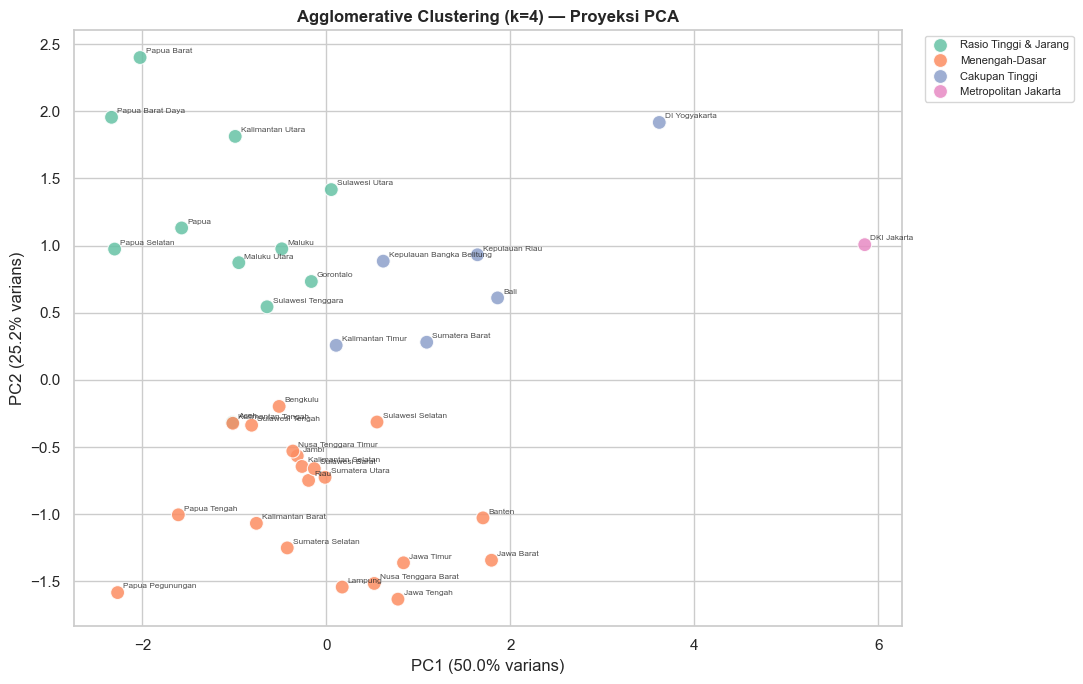

In [8]:
pca = PCA(n_components=2, random_state=42)
pcs = pca.fit_transform(X)
df["pc1"], df["pc2"] = pcs[:, 0], pcs[:, 1]

fig, ax = plt.subplots(figsize=(11, 7))
sns.scatterplot(data=df, x="pc1", y="pc2", hue="cluster_label", palette="Set2",
                s=100, alpha=0.85, ax=ax)
for _, row in df.iterrows():
    ax.annotate(row["Provinsi"], (row["pc1"], row["pc2"]),
                xytext=(4, 3), textcoords="offset points", fontsize=6, alpha=0.8)
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% varians)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% varians)")
ax.set_title(f"Agglomerative Clustering (k={k_best}) — Proyeksi PCA", weight="bold")
ax.legend(fontsize=8, bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
fig.savefig(FIG_DIR / "pca_cluster.png", dpi=150)
plt.show()

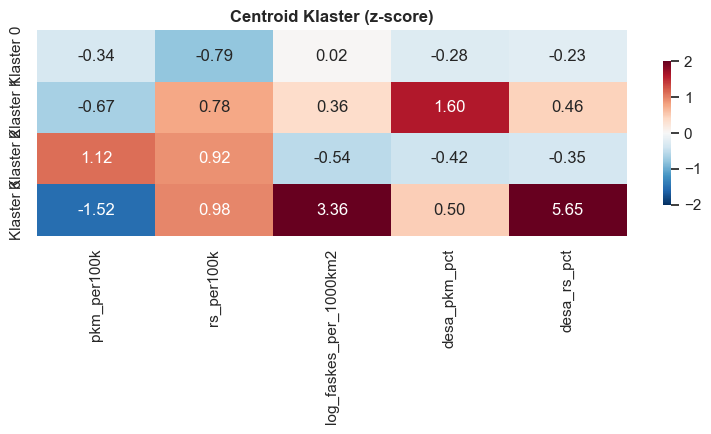

In [9]:
centroids = pd.DataFrame(model.cluster_centers_ if hasattr(model, "cluster_centers_")
                         else df.groupby("cluster")[SCALED_COLS].mean().to_numpy(),
                         index=[f"Klaster {i}" for i in range(k_best)],
                         columns=CLUSTER_COLS)

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.heatmap(centroids, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-2, vmax=2,
            center=0, cbar_kws={"shrink": .7}, ax=ax)
ax.set_title("Centroid Klaster (z-score)", weight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "centroid_klaster.png", dpi=150)
plt.show()

### 3.5 Simpan hasil

In [10]:
members = df[["Provinsi", "cluster", "cluster_label", "pc1", "pc2"]].sort_values(
    ["cluster", "Provinsi"])
members.to_csv(TABLE_DIR / "anggota_klaster.csv", index=False)

# Salin label klaster ke dataset fitur agar bisa dipakai dashboard
out_features = df.drop(columns=["pc1", "pc2"]).copy()
out_features.to_csv(PROCESSED / "faskes_features_clustered.csv", index=False)

print("Tabel tersimpan:")
print(" -", TABLE_DIR / "anggota_klaster.csv")
print(" -", TABLE_DIR / "profil_klaster.csv")
print(" -", PROCESSED / "faskes_features_clustered.csv")
display(members)

Tabel tersimpan:
 - C:\Users\LENOVO\OneDrive\Documents\KULIAH COYYY\SEMESTER 5\Presentasi Data & Storytelling\pemerataan-faskes-indonesia\outputs\tables\anggota_klaster.csv
 - C:\Users\LENOVO\OneDrive\Documents\KULIAH COYYY\SEMESTER 5\Presentasi Data & Storytelling\pemerataan-faskes-indonesia\outputs\tables\profil_klaster.csv
 - C:\Users\LENOVO\OneDrive\Documents\KULIAH COYYY\SEMESTER 5\Presentasi Data & Storytelling\pemerataan-faskes-indonesia\data\processed\faskes_features_clustered.csv


,Provinsi,cluster,cluster_label,pc1,pc2
15,Banten,0,Menengah-Dasar,1.702505,-1.027805
6,Bengkulu,0,Menengah-Dasar,-0.514018,-0.197782
4,Jambi,0,Menengah-Dasar,-0.317062,-0.566332
11,Jawa Barat,0,Menengah-Dasar,1.795043,-1.343266
12,Jawa Tengah,0,Menengah-Dasar,0.778009,-1.633100
14,Jawa Timur,0,Menengah-Dasar,0.838377,-1.362398
19,Kalimantan Barat,0,Menengah-Dasar,-0.761379,-1.068332
21,Kalimantan Selatan,0,Menengah-Dasar,-0.264963,-0.644992
20,Kalimantan Tengah,0,Menengah-Dasar,-1.017718,-0.323322
7,Lampung,0,Menengah-Dasar,0.171583,-1.542915


## 4. Interpretasi & rekomendasi kebijakan

1. **Ketimpangan struktural**: Gini dan rasio max/min menunjukkan faskes terkonsentrasi
   di provinsi padat; pemerataan tidak cukup diukur dengan jumlah total.
2. **Dua jenis kesenjangan**:
   - *Kesenjangan kapasitas* di klaster Menengah-Dasar (akses per kapita & cakupan rendah).
   - *Kesenjangan keterjangkauan* di klaster Rasio Tinggi & Jarang (rasio tinggi, tetapi
     kepadatan dan cakupan RS rendah).
3. **Klaster Cakupan Tinggi** dapat dijadikan benchmark praktik (mis. Sumbar, Bali, DIY).
4. **DKI Jakarta** memerlukan indikator berbeda (klinik/RS, bukan puskesmas per kapita).
5. **Prioritas alokasi**: provinsi dengan `pkm_gap` positif besar **dan** cakupan desa rendah.

### Keterbatasan
- Data agregat provinsi; heterogenitas kabupaten/kota tidak terlihat.
- Standar Permenkes berbasis populasi, belum memperhitungkan waktu tempuh/geografi.
- Klaster bergantung pada pilihan fitur dan transformasi; uji sensitivitas disarankan
  (mis. tanpa DKI Jakarta, atau linkage average/complete).
- Beberapa indikator saling berkorelasi (lihat notebook 03), sehingga bobot tiap dimensi
  tidak sepenuhnya independen.

## Referensi
- Permenkes No. 70 Tahun 2016 tentang Standar Pelayanan Minimal (1 puskesmas per 30.000 penduduk).
- BPS, proyeksi penduduk provinsi 2025–2026.
- Kemenkes, data sarana kesehatan desa/kelurahan 2025.
- Ward, J. H. (1963). Hierarchical grouping to optimize an objective function.